In [1]:
import numpy as np
import prisonersdilemma as pd
from  numba import njit
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from matplotlib.colors import Normalize


In [2]:
Player = pd.Player
PrisonersDilemma = pd.PrisonersDilemma
Operator = pd.Operator

In [3]:
class Adam:
    def __init__(
            self,
            learning_rate:float = 0.001,
            beta1:float = 0.1,
            beta2:float = 0.999,
            eps:float = 1e-8
            ):

        self.learning_rate = learning_rate
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps


        self.m = None
        self.v = None
        self.t = 0

    def step(self,params:np.ndarray,gradient:np.ndarray)-> np.ndarray:

        if self.m is None:
            self.m = np.zeros_like(params,dtype=float)
            self.v = np.zeros_like(params,dtype=float)
        self.t += 1 

        self.m = (self.beta1 * self.m + (1.0 - self.beta1) * gradient) 
        self.v = (self.beta2 * self.v + (1.0 - self.beta2) * gradient**2)


        m_hat = self.m / (1.0 - self.beta1**self.t)
        v_hat = self.v / (1.0 - self.beta2**self.t)


        update = (
            self.learning_rate * m_hat / (np.sqrt(v_hat) + self.eps)
        )

        params = params + update

        return params
        

In [4]:
class QuantumGameEvaluator:
    def __init__(self,gamma:float):

        self.game = pd.PrisonersDilemma(gamma)
        self.alice = Player()
        self.bob = Player()


    @staticmethod
    def create_player(params:np.ndarray)->Player:
        theta, alpha, beta = params
        player = Player()
        player.set(theta, alpha, beta)
        return player

    def evaluate(self, alice_params:np.ndarray, bob_params:np.ndarray)->tuple[float,float]:
        self.alice.set(*alice_params)
        self.bob.set(*bob_params)



        state = self.game.run(self.alice,self.bob)
        probs = self.game.compute_probabilities(state)
        alice_reward, bob_reward = self.game.compute_payoffs(probs)
        return alice_reward, bob_reward



    # @staticmethod
    # def enforce_parameter_bounds(parameters: np.ndarray) -> np.ndarray:
    #     parameters[0] = reflect(parameters[0], 0.0, np.pi)
    #     parameters[1] = (parameters[1] + np.pi) % (2.0 * np.pi) - np.pi
    #     parameters[2] = (parameters[2] + np.pi) % (2.0 * np.pi) - np.pi

    #     return parameters


    # @staticmethod
    # def enforce_parameter_bounds(parameters: np.ndarray) -> np.ndarray:
    #     parameters[0] %= np.pi
    #     parameters[1] = (parameters[1] + np.pi) % (2.0 * np.pi) - np.pi
    #     parameters[2] = (parameters[2] + np.pi) % (2.0 * np.pi) - np.pi

    #     return parameters

    # @staticmethod
    # def enforce_parameter_bounds(parameters: np.ndarray) -> np.ndarray:
    #     parameters[0] = np.clip(parameters[0],0,np.pi)
    #     parameters[1] = (parameters[1] + np.pi) % (2.0 * np.pi) - np.pi
    #     parameters[2] = (parameters[2] + np.pi) % (2.0 * np.pi) - np.pi

    #     return parameters


    # @staticmethod
    # def enforce_parameter_bounds(parameters:np.ndarray)-> np.ndarray:
    #     parameters[0] = np.clip(parameters[0],0.0,np.pi)
    #     parameters[1] = np.clip(parameters[1],-np.pi,np.pi)
    #     parameters[2] = np.clip(parameters[2],-np.pi,np.pi)
    #     return parameters

    @staticmethod
    def enforce_parameter_bounds(parameters: np.ndarray) -> np.ndarray:
        parameters[0] = np.clip(parameters[0], 0.0, np.pi)

        parameters[1] = parameters[1] % (2.0 * np.pi)
        parameters[2] = parameters[2] % (2.0 * np.pi)

        return parameters


In [5]:
# Forward Difference

# class FiniteDifferenceGradient:
#     def __init__(self,evaluator:QuantumGameEvaluator,epsilon:float=1e-8):
#         self.evaluator = evaluator
#         self.epsilon = epsilon

#     def alice_gradient(self,alice_params:np.ndarray,bob_params:np.ndarray):
#         gradient = np.zeros(3,dtype=float)


#         current_alice_reward, _ = (
#             self.evaluator.evaluate(alice_params,bob_params)
#         )


#         for i in range(3):

#             alice_modified = alice_params.copy()

#             alice_modified[i] += self.epsilon


#             modified_alice_reward,_ = self.evaluator.evaluate(alice_modified,bob_params)

#             gradient[i] = (modified_alice_reward - current_alice_reward) / self.epsilon

#         return gradient
            
#     def bob_gradient(self,alice_params:np.ndarray,bob_params:np.ndarray):
#         gradient = np.zeros(3,dtype=float)


#         _, current_bob_reward = (
#             self.evaluator.evaluate(alice_params,bob_params)
#         )


#         for i in range(3):

#             bob_modified = bob_params.copy()

#             bob_modified[i] += self.epsilon


#             _, modified_bob_reward = self.evaluator.evaluate(alice_params,bob_modified)

#             gradient[i] = (modified_bob_reward - current_bob_reward) / self.epsilon

#         return gradient



# Central Difference
class FiniteDifferenceGradient:
    def __init__(
        self,
        evaluator: QuantumGameEvaluator,
        epsilon: float = 1e-5
    ):
        self.evaluator = evaluator
        self.epsilon = epsilon

    # ============================================================
# Central Finite Difference Gradient
# ============================================================

class FiniteDifferenceGradient:

    def __init__(
        self,
        evaluator: QuantumGameEvaluator,
        epsilon: float = 1e-5
    ):
        self.evaluator = evaluator
        self.epsilon = epsilon


    def compute(
        self,
        alice_params: np.ndarray,
        bob_params: np.ndarray
    ) -> tuple[np.ndarray, np.ndarray]:

        alice_gradient = np.zeros(3, dtype=float)
        bob_gradient = np.zeros(3, dtype=float)

        # ====================================================
        # Calculate Alice and Bob gradients
        # ====================================================

        for i in range(3):

            # ------------------------------------------------
            # Alice perturbation
            # ------------------------------------------------

            alice_plus = alice_params.copy()
            alice_minus = alice_params.copy()

            alice_plus[i] += self.epsilon
            alice_minus[i] -= self.epsilon

            alice_plus = self.evaluator.enforce_parameter_bounds(alice_plus)
            alice_minus = self.evaluator.enforce_parameter_bounds(alice_minus)

            alice_plus_payoff, _ = self.evaluator.evaluate(
                alice_plus,
                bob_params
            )

            alice_minus_payoff, _ = self.evaluator.evaluate(
                alice_minus,
                bob_params
            )

            alice_gradient[i] = (
                alice_plus_payoff
                - alice_minus_payoff
            ) / (2.0 * self.epsilon)

            # ------------------------------------------------
            # Bob perturbation
            # ------------------------------------------------

            bob_plus = bob_params.copy()
            bob_minus = bob_params.copy()

            bob_plus[i] += self.epsilon
            bob_minus[i] -= self.epsilon

            bob_plus = self.evaluator.enforce_parameter_bounds(bob_plus)
            bob_minus = self.evaluator.enforce_parameter_bounds(bob_minus)

            _, bob_plus_payoff = self.evaluator.evaluate(
                alice_params,
                bob_plus
            )

            _, bob_minus_payoff = self.evaluator.evaluate(
                alice_params,
                bob_minus
            )

            bob_gradient[i] = (
                bob_plus_payoff
                - bob_minus_payoff
            ) / (2.0 * self.epsilon)

        return alice_gradient, bob_gradient


In [6]:
class QuantumGameLearner:

    def __init__(
        self,
        gamma: float,
        learning_rate: float = 1e-4,
        finite_difference_epsilon: float = 1e-5
    ):

        self.evaluator = QuantumGameEvaluator(gamma)

        self.gradient = FiniteDifferenceGradient(
            self.evaluator,
            epsilon=finite_difference_epsilon
        )

        self.alice_optimizer = Adam(
            learning_rate=learning_rate
        )

        self.bob_optimizer = Adam(
            learning_rate=learning_rate
        )

    def check_nash_equilibrium(
        self,
        alice: np.ndarray,
        bob: np.ndarray,
        tolerance: float = 1e-4,
        n_samples: int = 5000
    ):

        current_alice_payoff, current_bob_payoff = self.play_round(
            alice,
            bob
        )

        random_alice = np.empty((n_samples, 3), dtype=np.float64)
        random_bob = np.empty((n_samples, 3), dtype=np.float64)

        random_alice[:, 0] = np.random.uniform(
            0.0,
            np.pi,
            n_samples
        )

        random_bob[:, 0] = np.random.uniform(
            0.0,
            np.pi,
            n_samples
        )

        random_alice[:, 1] = np.random.uniform(
            0.0,
            2.0 * np.pi,
            n_samples
        )

        random_bob[:, 1] = np.random.uniform(
            0.0,
            2.0 * np.pi,
            n_samples
        )

        random_alice[:, 2] = np.random.uniform(
            0.0,
            2.0 * np.pi,
            n_samples
        )

        random_bob[:, 2] = np.random.uniform(
            0.0,
            2.0 * np.pi,
            n_samples
        )

        best_alice_payoff = current_alice_payoff
        best_alice_strategy = alice.copy()

        for candidate in random_alice:

            candidate_payoff, _ = self.play_round(
                candidate,
                bob
            )

            if candidate_payoff > best_alice_payoff:

                best_alice_payoff = candidate_payoff
                best_alice_strategy = candidate.copy()

        best_bob_payoff = current_bob_payoff
        best_bob_strategy = bob.copy()

        for candidate in random_bob:

            _, candidate_payoff = self.play_round(
                alice,
                candidate
            )

            if candidate_payoff > best_bob_payoff:

                best_bob_payoff = candidate_payoff
                best_bob_strategy = candidate.copy()

        alice_gain = (
            best_alice_payoff
            - current_alice_payoff
        )

        bob_gain = (
            best_bob_payoff
            - current_bob_payoff
        )

        alice_can_improve = (
            alice_gain > tolerance
        )

        bob_can_improve = (
            bob_gain > tolerance
        )

        is_nash = (
            not alice_can_improve
            and
            not bob_can_improve
        )

        return (
            is_nash,
            alice_can_improve,
            bob_can_improve,
            alice_gain,
            bob_gain,
            best_alice_strategy,
            best_bob_strategy
        )

    def play_round(
        self,
        alice_params: np.ndarray,
        bob_params: np.ndarray
    ):

        return self.evaluator.evaluate(
            alice_params=alice_params,
            bob_params=bob_params
        )

    def train(
        self,
        alice_initial: np.ndarray,
        bob_initial: np.ndarray,
        iterations: int = 10_000,
        verbose: int = 100,
        gradient_tolerance: float = 1e-4,
        stable_iterations: int = 1000,
        nash_tolerance: float = 1e-4,
        nash_samples: int = 5000
    ):

        alice = np.array(
            alice_initial,
            dtype=float
        )

        bob = np.array(
            bob_initial,
            dtype=float
        )

        alice = self.evaluator.enforce_parameter_bounds(
            alice
        )

        bob = self.evaluator.enforce_parameter_bounds(
            bob
        )

        alice_history = np.empty(
            (iterations, 3),
            dtype=np.float64
        )

        bob_history = np.empty(
            (iterations, 3),
            dtype=np.float64
        )

        alice_payoff_history = np.empty(
            iterations,
            dtype=np.float64
        )

        bob_payoff_history = np.empty(
            iterations,
            dtype=np.float64
        )

        alice_gradient_history = np.empty(
            (iterations, 3),
            dtype=np.float64
        )

        bob_gradient_history = np.empty(
            (iterations, 3),
            dtype=np.float64
        )

        converged = False
        final_iteration = iterations
        stable_count = 0

        alice_gradient = np.zeros(
            3,
            dtype=float
        )

        bob_gradient = np.zeros(
            3,
            dtype=float
        )

        alice_payoff = 0.0
        bob_payoff = 0.0

        for iteration in range(iterations):

            alice_payoff, bob_payoff = self.play_round(
                alice,
                bob
            )

            alice_gradient, bob_gradient = self.gradient.compute(
                alice,
                bob
            )

            alice_gradient_norm = np.linalg.norm(
                alice_gradient
            )

            bob_gradient_norm = np.linalg.norm(
                bob_gradient
            )

            new_alice = self.alice_optimizer.step(
                alice.copy(),
                alice_gradient
            )

            new_bob = self.bob_optimizer.step(
                bob.copy(),
                bob_gradient
            )

            new_alice = self.evaluator.enforce_parameter_bounds(
                new_alice
            )

            new_bob = self.evaluator.enforce_parameter_bounds(
                new_bob
            )

            alice_change = np.linalg.norm(
                new_alice - alice
            )

            bob_change = np.linalg.norm(
                new_bob - bob
            )

            alice = new_alice
            bob = new_bob

            alice_payoff, bob_payoff = self.play_round(
                alice,
                bob
            )

            alice_history[iteration] = alice
            bob_history[iteration] = bob

            alice_payoff_history[iteration] = alice_payoff
            bob_payoff_history[iteration] = bob_payoff

            alice_gradient_history[iteration] = alice_gradient
            bob_gradient_history[iteration] = bob_gradient

            gradient_small = (
                alice_gradient_norm < gradient_tolerance
                and
                bob_gradient_norm < gradient_tolerance
            )

            if gradient_small:

                stable_count += 1

            else:

                stable_count = 0

            if (
                verbose is not None
                and
                iteration % verbose == 0
            ):

                print(
                    f"Iteration {iteration:8d} | "
                    f"Alice = {alice_payoff:10.6f} | "
                    f"Bob = {bob_payoff:10.6f}"
                )

                print(
                    f"    Alice: "
                    f"theta={alice[0]:.6f}, "
                    f"alpha={alice[1]:.6f}, "
                    f"beta={alice[2]:.6f}"
                )

                print(
                    f"    Bob:   "
                    f"theta={bob[0]:.6f}, "
                    f"alpha={bob[1]:.6f}, "
                    f"beta={bob[2]:.6f}"
                )

                print(
                    f"    |grad Alice| = "
                    f"{alice_gradient_norm:.8e}"
                )

                print(
                    f"    |grad Bob|   = "
                    f"{bob_gradient_norm:.8e}"
                )

                print(
                    f"    ΔAlice       = "
                    f"{alice_change:.8e}"
                )

                print(
                    f"    ΔBob         = "
                    f"{bob_change:.8e}"
                )

                print(
                    f"    Stable gradient iterations = "
                    f"{stable_count}/{stable_iterations}"
                )

            if stable_count >= stable_iterations:

                print()
                print("=" * 70)
                print(
                    "Gradient convergence condition satisfied."
                )
                print(
                    f"Checking Nash equilibrium at iteration "
                    f"{iteration}..."
                )
                print("=" * 70)

                (
                    is_nash,
                    alice_can_improve,
                    bob_can_improve,
                    alice_gain,
                    bob_gain,
                    best_alice_strategy,
                    best_bob_strategy
                ) = self.check_nash_equilibrium(
                    alice,
                    bob,
                    tolerance=nash_tolerance,
                    n_samples=nash_samples
                )

                if is_nash:

                    print()
                    print("=" * 70)
                    print("NUMERICAL NASH EQUILIBRIUM FOUND")
                    print("=" * 70)

                    print(
                        f"Iteration: {iteration}"
                    )

                    print("\nAlice strategy:")

                    print(
                        f"    theta = {alice[0]:.10f}\n"
                        f"    alpha = {alice[1]:.10f}\n"
                        f"    beta  = {alice[2]:.10f}"
                    )

                    print("\nBob strategy:")

                    print(
                        f"    theta = {bob[0]:.10f}\n"
                        f"    alpha = {bob[1]:.10f}\n"
                        f"    beta  = {bob[2]:.10f}"
                    )

                    print("\nPayoffs:")

                    print(
                        f"    Alice = {alice_payoff:.10f}\n"
                        f"    Bob   = {bob_payoff:.10f}"
                    )

                    print("\nGradients:")

                    print(
                        f"    Alice = {alice_gradient}"
                    )

                    print(
                        f"    Bob   = {bob_gradient}"
                    )

                    print("\nGradient norms:")

                    print(
                        f"    Alice = "
                        f"{alice_gradient_norm:.10e}\n"
                        f"    Bob   = "
                        f"{bob_gradient_norm:.10e}"
                    )

                    print("\nBest sampled payoffs:")

                    print(
                        f"    Alice = "
                        f"{alice_payoff + alice_gain:.10f}\n"
                        f"    Bob   = "
                        f"{bob_payoff + bob_gain:.10f}"
                    )

                    print("\nMaximum unilateral gains:")

                    print(
                        f"    Alice = "
                        f"{alice_gain:.10e}\n"
                        f"    Bob   = "
                        f"{bob_gain:.10e}"
                    )

                    print("=" * 70)

                    converged = True
                    final_iteration = iteration + 1

                    break

                else:

                    print()
                    print("-" * 70)
                    print(
                        "Gradient convergence reached, "
                        "but Nash equilibrium was NOT verified."
                    )

                    print(
                        f"Alice maximum sampled gain = "
                        f"{alice_gain:.10e}"
                    )

                    print(
                        f"Bob maximum sampled gain   = "
                        f"{bob_gain:.10e}"
                    )

                    print(
                        "Continuing training..."
                    )

                    print("-" * 70)

                    stable_count = 0

        if not converged:

            final_iteration = iterations

            print()
            print("=" * 70)
            print(
                "TRAINING FINISHED WITHOUT VERIFIED NE"
            )
            print("=" * 70)

            print(
                f"Maximum iterations: {iterations}"
            )

            print("\nFinal Alice strategy:")

            print(
                f"    theta = {alice[0]:.10f}\n"
                f"    alpha = {alice[1]:.10f}\n"
                f"    beta  = {alice[2]:.10f}"
            )

            print("\nFinal Bob strategy:")

            print(
                f"    theta = {bob[0]:.10f}\n"
                f"    alpha = {bob[1]:.10f}\n"
                f"    beta  = {bob[2]:.10f}"
            )

            print("\nFinal payoffs:")

            print(
                f"    Alice = {alice_payoff:.10f}\n"
                f"    Bob   = {bob_payoff:.10f}"
            )

            print("\nFinal gradient norms:")

            print(
                f"    Alice = "
                f"{np.linalg.norm(alice_gradient):.10e}\n"
                f"    Bob   = "
                f"{np.linalg.norm(bob_gradient):.10e}"
            )

            print("=" * 70)

        alice_history = alice_history[
            :final_iteration
        ]

        bob_history = bob_history[
            :final_iteration
        ]

        alice_payoff_history = alice_payoff_history[
            :final_iteration
        ]

        bob_payoff_history = bob_payoff_history[
            :final_iteration
        ]

        alice_gradient_history = alice_gradient_history[
            :final_iteration
        ]

        bob_gradient_history = bob_gradient_history[
            :final_iteration
        ]

        return (
            np.array(alice_history),
            np.array(bob_history),
            np.array(alice_payoff_history),
            np.array(bob_payoff_history),
            np.array(alice_gradient_history),
            np.array(bob_gradient_history)
        )

In [7]:

gamma = np.pi/2


# ---------------------------------------------------------------
# Random initialization
#
# The paper states that every player starts with a randomly
# selected set of actions.
# ---------------------------------------------------------------

rng = np.random.default_rng()


alice_initial = np.array([
    rng.uniform(0.0, np.pi),
    rng.uniform(0,  2 * np.pi),
    rng.uniform(0,  2 * np.pi)
])

bob_initial = np.array([
    rng.uniform(0.0, np.pi),
    rng.uniform(0,  2 * np.pi),
    rng.uniform(0,  2 * np.pi)
])

alice_params = np.array([0.626890289329418, 4.70964803935234, 2.3624823794904204])
bob_params = np.array([1.773293566564791, 1.0395646236313205, 3.9735293058909176])


# alice_initial =[0.280065,   0.5355038,  6.03392693] 
# bob_initial =[3.09810192, 2.54802489, 5.67463534] 


print("Initial Alice:")
print(alice_initial)

print("\nInitial Bob:")
print(bob_initial)


# ---------------------------------------------------------------
# Learner
# ---------------------------------------------------------------

learner = QuantumGameLearner(

    gamma=gamma,

    # Paper alpha_1
    learning_rate=1e-4,

    # Paper finite-difference epsilon
    finite_difference_epsilon=1e-5
)


# ---------------------------------------------------------------
# Train
# ---------------------------------------------------------------

(
    alice_history,
    bob_history,
    alice_payoff_history,
    bob_payoff_history,
    alice_grad_history,
    bob_grad_history
) = learner.train(

    alice_initial=alice_initial,

    bob_initial=bob_initial,
    # Paper uses 1,000,000 iterations
    iterations=500_000,

    verbose=50000
)


# %%
# ================================================================
# 6. FINAL RESULTS
# ================================================================

print(
    "\n================ FINAL RESULTS ================"
)


print("\nAlice:")

print(
    f"theta = {alice_history[-1, 0]:.10f}"
)

print(
    f"alpha = {alice_history[-1, 1]:.10f}"
)

print(
    f"beta  = {alice_history[-1, 2]:.10f}"
)



print("\nBob:")

print(
    f"theta = {bob_history[-1, 0]:.10f}"
)

print(
    f"alpha = {bob_history[-1, 1]:.10f}"
)

print(
    f"beta  = {bob_history[-1, 2]:.10f}"
)


print("\nFinal rewards:")

print(
    f"Alice = "
    f"{alice_payoff_history[-1]:.10f}"
)

print(
    f"Bob   = "
    f"{bob_payoff_history[-1]:.10f}"
)


print("\nFinal gradients:")

print(
    "Alice:",
    alice_grad_history[-1]
)

print(
    "Bob:  ",
    bob_grad_history[-1]
)


Initial Alice:
[2.53471896 1.40708664 4.63240363]

Initial Bob:
[0.15773392 3.07020995 0.48335015]
Iteration        0 | Alice =   0.163119 | Bob =   4.550432
    Alice: theta=2.534619, alpha=1.406987, beta=4.632304
    Bob:   theta=0.157634, alpha=3.070110, beta=0.483250
    |grad Alice| = 4.89996496e-01
    |grad Bob|   = 7.86186469e-01
    ΔAlice       = 1.73205074e-04
    ΔBob         = 1.73205074e-04
    Stable gradient iterations = 0/1000
Iteration    50000 | Alice =   1.196347 | Bob =   4.196249
    Alice: theta=0.000000, alpha=2.698506, beta=1.971348
    Bob:   theta=1.787290, alpha=0.442411, beta=5.918348
    |grad Alice| = 8.67801432e-01
    |grad Bob|   = 1.07191775e+00
    ΔAlice       = 1.08397159e-04
    ΔBob         = 1.82314516e-04
    Stable gradient iterations = 0/1000
Iteration   100000 | Alice =   0.885997 | Bob =   4.197166
    Alice: theta=2.202503, alpha=0.726208, beta=3.848120
    Bob:   theta=0.610614, alpha=2.040758, beta=2.671628
    |grad Alice| = 2.45339181e

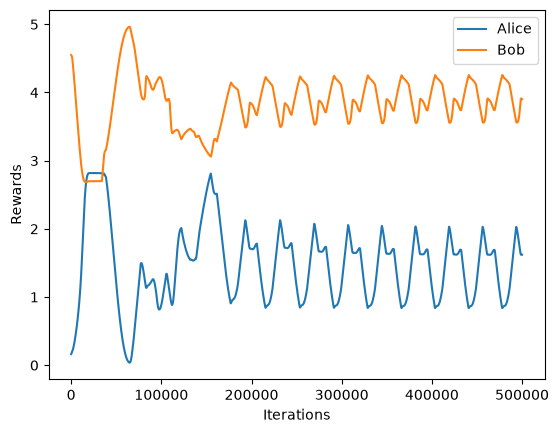

In [8]:
import matplotlib.pyplot as plt


plt.plot(alice_payoff_history,label="Alice")
plt.plot(bob_payoff_history,label="Bob")
plt.xlabel("Iterations")
plt.ylabel("Rewards")
plt.legend()
plt.show()

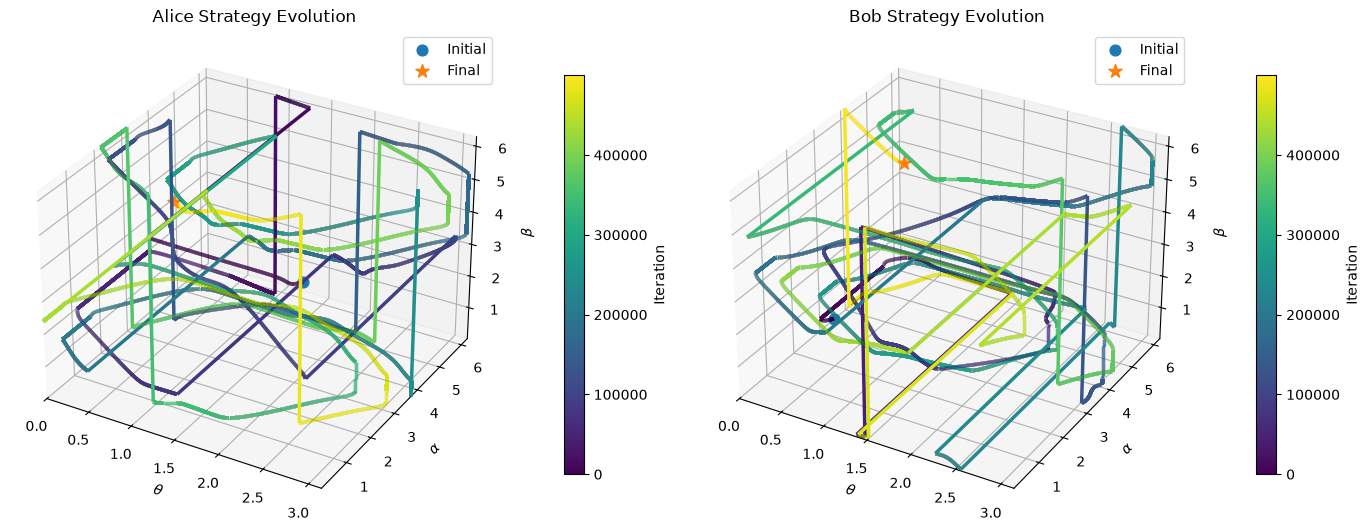

In [9]:

# ------------------------------------------------
# Create gradient 3D trajectory
# ------------------------------------------------
def plot_gradient_trajectory(ax, history, label):
    # Consecutive points
    points = history.reshape(-1, 1, 3)

    # Line segments between consecutive iterations
    segments = np.concatenate(
        [points[:-1], points[1:]],
        axis=1
    )

    # Normalize iteration number: 0 -> 1
    norm = Normalize(
        vmin=0,
        vmax=len(history) - 1
    )

    # Gradient based on iteration
    lc = Line3DCollection(
        segments,
        cmap="viridis",
        norm=norm,
        linewidth=2.5
    )

    lc.set_array(np.arange(len(history) - 1))

    ax.add_collection3d(lc)

    # Initial point
    ax.scatter(
        history[0, 0],
        history[0, 1],
        history[0, 2],
        marker="o",
        s=60,
        label="Initial"
    )

    # Final point
    ax.scatter(
        history[-1, 0],
        history[-1, 1],
        history[-1, 2],
        marker="*",
        s=100,
        label="Final"
    )

    # Set limits because add_collection3d doesn't automatically
    # determine them reliably
    ax.set_xlim(history[:, 0].min(), history[:, 0].max())
    ax.set_ylim(history[:, 1].min(), history[:, 1].max())
    ax.set_zlim(history[:, 2].min(), history[:, 2].max())

    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel(r"$\alpha$")
    ax.set_zlabel(r"$\beta$")
    ax.set_title(label)
    ax.legend()

    return lc


# ------------------------------------------------
# Create two 3D plots
# ------------------------------------------------
fig = plt.figure(figsize=(14, 6))

# =================================================
# Alice
# =================================================
ax1 = fig.add_subplot(121, projection="3d")

lc1 = plot_gradient_trajectory(
    ax1,
    alice_history,
    "Alice Strategy Evolution"
)

# =================================================
# Bob
# =================================================
ax2 = fig.add_subplot(122, projection="3d")

lc2 = plot_gradient_trajectory(
    ax2,
    bob_history,
    "Bob Strategy Evolution"
)

# ------------------------------------------------
# Colorbars
# ------------------------------------------------
cbar1 = fig.colorbar(
    lc1,
    ax=ax1,
    pad=0.1,
    shrink=0.7
)
cbar1.set_label("Iteration")

cbar2 = fig.colorbar(
    lc2,
    ax=ax2,
    pad=0.1,
    shrink=0.7
)
cbar2.set_label("Iteration")

plt.tight_layout()
plt.show()

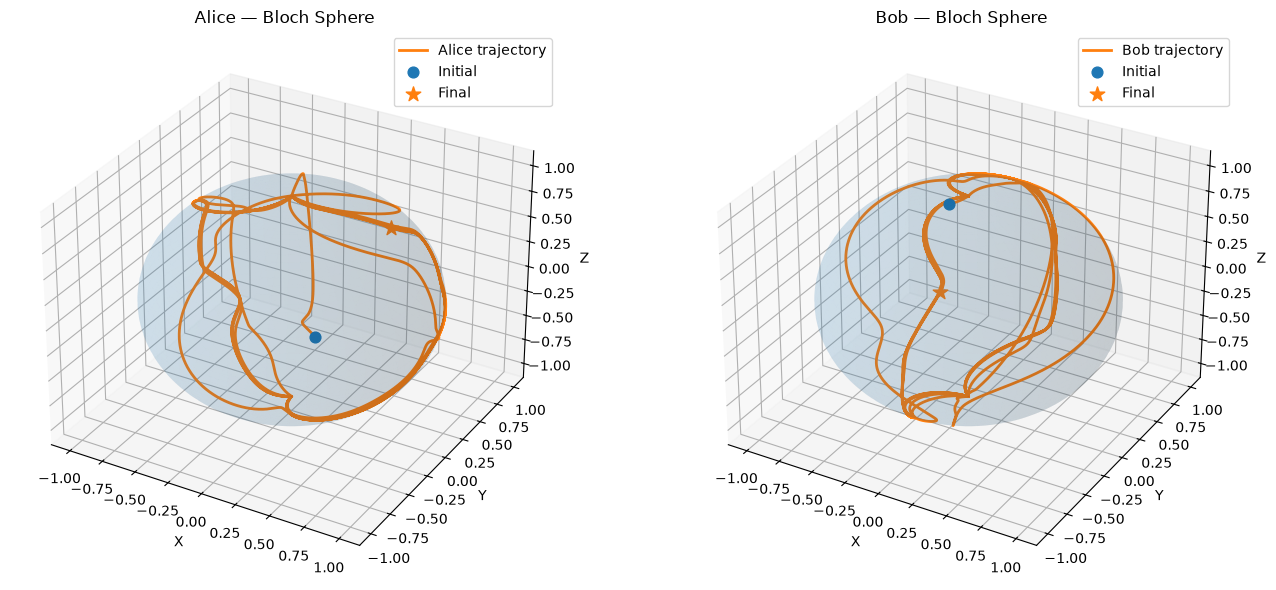

In [10]:


def bloch_coordinates(history):

    theta = history[:, 0]
    alpha = history[:, 1]
    beta = history[:, 2]

    x = np.sin(theta) * np.sin(alpha + beta)
    y = np.sin(theta) * np.cos(alpha + beta)
    z = np.cos(theta)

    return x, y, z


alice_x, alice_y, alice_z = bloch_coordinates(alice_history)
bob_x, bob_y, bob_z = bloch_coordinates(bob_history)


# Sphere
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 50)

X = np.outer(np.cos(u), np.sin(v))
Y = np.outer(np.sin(u), np.sin(v))
Z = np.outer(np.ones_like(u), np.cos(v))


fig = plt.figure(figsize=(14, 6))


# ============================================================
# Alice
# ============================================================

ax1 = fig.add_subplot(121, projection="3d")

ax1.plot_surface(
    X, Y, Z,
    alpha=0.1
)

ax1.plot(
    alice_x,
    alice_y,
    alice_z,
    linewidth=2,
    label="Alice trajectory"
)

ax1.scatter(
    alice_x[0],
    alice_y[0],
    alice_z[0],
    s=60,
    label="Initial"
)

ax1.scatter(
    alice_x[-1],
    alice_y[-1],
    alice_z[-1],
    marker="*",
    s=120,
    label="Final"
)

ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.set_title("Alice — Bloch Sphere")
ax1.legend()


# ============================================================
# Bob
# ============================================================

ax2 = fig.add_subplot(122, projection="3d")

ax2.plot_surface(
    X, Y, Z,
    alpha=0.1
)

ax2.plot(
    bob_x,
    bob_y,
    bob_z,
    linewidth=2,
    label="Bob trajectory"
)

ax2.scatter(
    bob_x[0],
    bob_y[0],
    bob_z[0],
    s=60,
    label="Initial"
)

ax2.scatter(
    bob_x[-1],
    bob_y[-1],
    bob_z[-1],
    marker="*",
    s=120,
    label="Final"
)

ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlabel("Z")
ax2.set_title("Bob — Bloch Sphere")
ax2.legend()


plt.tight_layout()
plt.show()

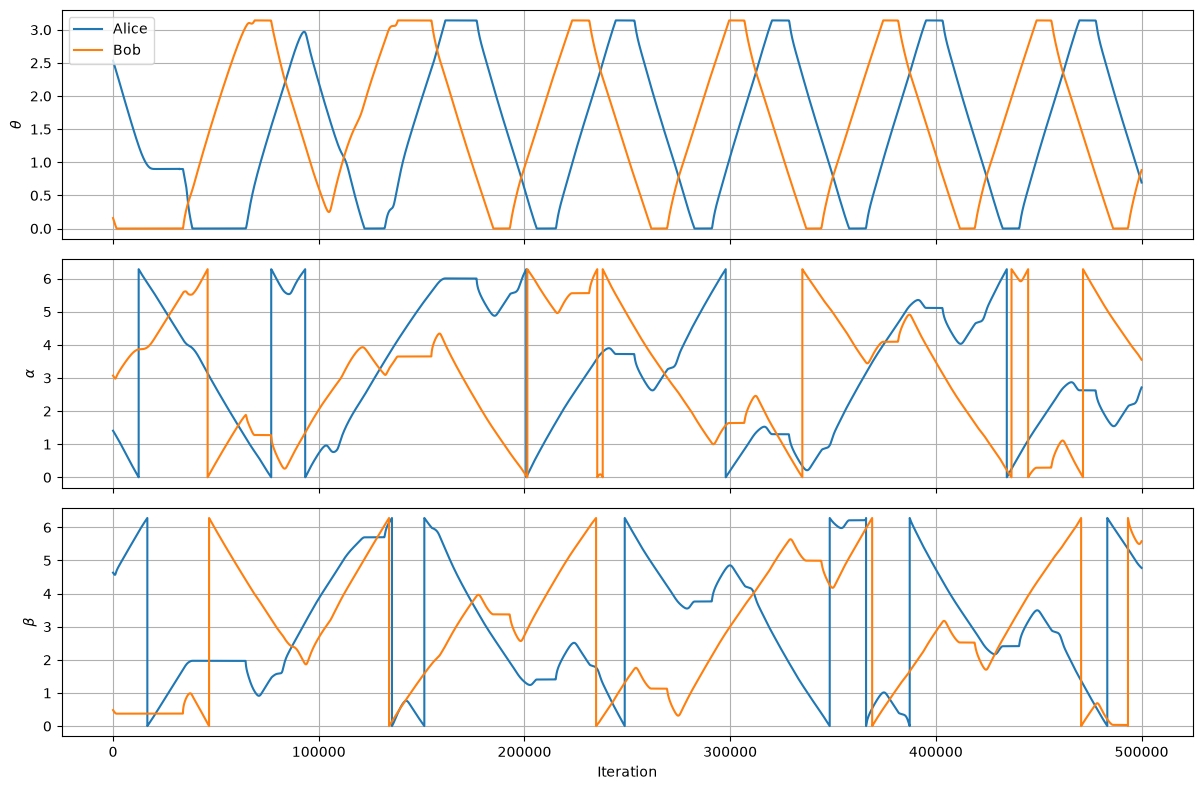

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

names = [r"$\theta$", r"$\alpha$", r"$\beta$"]

for i, name in enumerate(names):
    axes[i].plot(alice_history[:, i], label="Alice")
    axes[i].plot(bob_history[:, i], label="Bob")
    axes[i].set_ylabel(name)
    axes[i].grid(True)

axes[-1].set_xlabel("Iteration")
axes[0].legend()

plt.tight_layout()
plt.show()